In [8]:
import pandas as pd, numpy as np, joblib
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
import xgboost, lightgbm, shap, statsmodels, matplotlib, seaborn
print("all libraries ok")

all libraries ok


In [9]:
SEED = 42
df = pd.read_csv("bedtime_screentime_sleep_debt.csv")

print(df.shape)
print(df.dtypes)
print("missing:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())
print("duplicate user_id:", df["user_id"].duplicated().sum())

(8500, 18)
user_id                         str
age                           int64
gender                          str
occupation_type                 str
chronotype                      str
bedtime_phone_minutes         int64
primary_bedtime_app             str
screen_brightness_pct         int64
blue_light_filter_active      int64
caffeine_post_5pm_mg          int64
physical_activity_min         int64
sleep_latency_min           float64
total_sleep_hours           float64
deep_sleep_pct              float64
rem_sleep_pct               float64
morning_alarm_snoozes         int64
next_day_fatigue_score      float64
sleep_debt_category             str
dtype: object
missing: 0
duplicate rows: 0
duplicate user_id: 0


In [10]:
df = df.drop(columns=["user_id", "sleep_debt_category"])
print(df.shape)   # (8500, 16) before the flags; (8500, 18) after adding them

(8500, 16)


In [11]:
df["fatigue_at_floor"] = (df["next_day_fatigue_score"] <= 1.0).astype(int)
df["fatigue_at_cap"]   = (df["next_day_fatigue_score"] >= 10).astype(int)

print(df["next_day_fatigue_score"].min(), df["next_day_fatigue_score"].max())
print(df[["fatigue_at_floor", "fatigue_at_cap"]].sum())    # how many rows
print(df[["fatigue_at_floor", "fatigue_at_cap"]].mean())   # share of rows
print(df.shape)

1.0 10.0
fatigue_at_floor    2110
fatigue_at_cap       314
dtype: int64
fatigue_at_floor    0.248235
fatigue_at_cap      0.036941
dtype: float64
(8500, 18)


In [12]:
habits    = ["bedtime_phone_minutes", "caffeine_post_5pm_mg", "physical_activity_min",
             "screen_brightness_pct", "blue_light_filter_active"]
context   = ["age", "gender", "occupation_type", "chronotype"]
app       = ["primary_bedtime_app"]
mediators = ["sleep_latency_min", "total_sleep_hours"]
stage1_targets = mediators + ["morning_alarm_snoozes"]
outcome   = "next_day_fatigue_score"
flags     = ["fatigue_at_floor", "fatigue_at_cap"]
unused    = ["deep_sleep_pct", "rem_sleep_pct"]   # kept in df, not used as inputs

used = set(habits + context + app + stage1_targets + [outcome] + flags + unused)
print("unassigned columns:", set(df.columns) - used)   # should print set()

stage1_features = habits + context + app
stage2_features = habits + context + app + mediators

unassigned columns: set()


In [13]:
binary_cols = ["blue_light_filter_active"]
cat_cols    = ["gender", "occupation_type", "chronotype", "primary_bedtime_app"]

def build_preprocessor(features):
    num  = [c for c in features if c not in cat_cols + binary_cols]
    bin_ = [c for c in features if c in binary_cols]
    cat  = [c for c in features if c in cat_cols]
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("bin", "passthrough", bin_),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), cat),
    ])

In [14]:
train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["fatigue_at_floor"]
)
print(train_df.shape, test_df.shape)   # expect (6800, 18) and (1700, 18)
print(train_df["fatigue_at_floor"].mean(), test_df["fatigue_at_floor"].mean())  # both near 0.248

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# Quick pipeline test: Stage 1, predict sleep_latency_min with Ridge
pipe = Pipeline([("prep", build_preprocessor(stage1_features)), ("model", Ridge(alpha=1.0))])
scores = cross_val_score(pipe, train_df[stage1_features], train_df["sleep_latency_min"],
                         cv=cv, scoring="r2")
print("CV R2:", scores.round(3), "mean:", scores.mean().round(3))

# Save outputs for the group
df.to_csv("clean_df.csv", index=False)
train_df.to_csv("train.csv", index=False)
test_df.to_csv("test.csv", index=False)
joblib.dump(build_preprocessor(stage1_features), "preprocessor_stage1.joblib")
joblib.dump(build_preprocessor(stage2_features), "preprocessor_stage2.joblib")
joblib.dump({"stage1_features": stage1_features, "stage2_features": stage2_features,
             "mediators": mediators, "stage1_targets": stage1_targets,
             "outcome": outcome, "seed": SEED}, "column_groups.joblib")
print("saved")

(6800, 18) (1700, 18)
0.24823529411764705 0.24823529411764705
CV R2: [0.84  0.833 0.837 0.835 0.846] mean: 0.838
saved


In [15]:
# Verify saved split and run 5-fold CV for every target
train_df = pd.read_csv("train.csv"); test_df = pd.read_csv("test.csv")
print(train_df.shape, test_df.shape)
for t in stage1_targets + [outcome]:
    feats = stage1_features if t in stage1_targets else stage2_features
    pipe = Pipeline([("prep", build_preprocessor(feats)), ("model", Ridge(alpha=1.0))])
    r2 = cross_val_score(pipe, train_df[feats], train_df[t], cv=cv, scoring="r2")
    print(f"{t:25s} mean CV R2 = {r2.mean():.3f}")

(6800, 18) (1700, 18)
sleep_latency_min         mean CV R2 = 0.838
total_sleep_hours         mean CV R2 = 0.795
morning_alarm_snoozes     mean CV R2 = 0.651
next_day_fatigue_score    mean CV R2 = 0.897


In [17]:
# %% Cell 1: setup (new cell at the bottom of main.ipynb)
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
os.makedirs("figures", exist_ok=True)
eda = pd.read_csv("bedtime_screentime_sleep_debt.csv")
eda = eda.drop(columns=["user_id", "sleep_debt_category"])
 
numeric_cols = ["age", "bedtime_phone_minutes", "screen_brightness_pct", "caffeine_post_5pm_mg",
                "physical_activity_min", "sleep_latency_min", "total_sleep_hours",
                "deep_sleep_pct", "rem_sleep_pct", "morning_alarm_snoozes", "next_day_fatigue_score"]

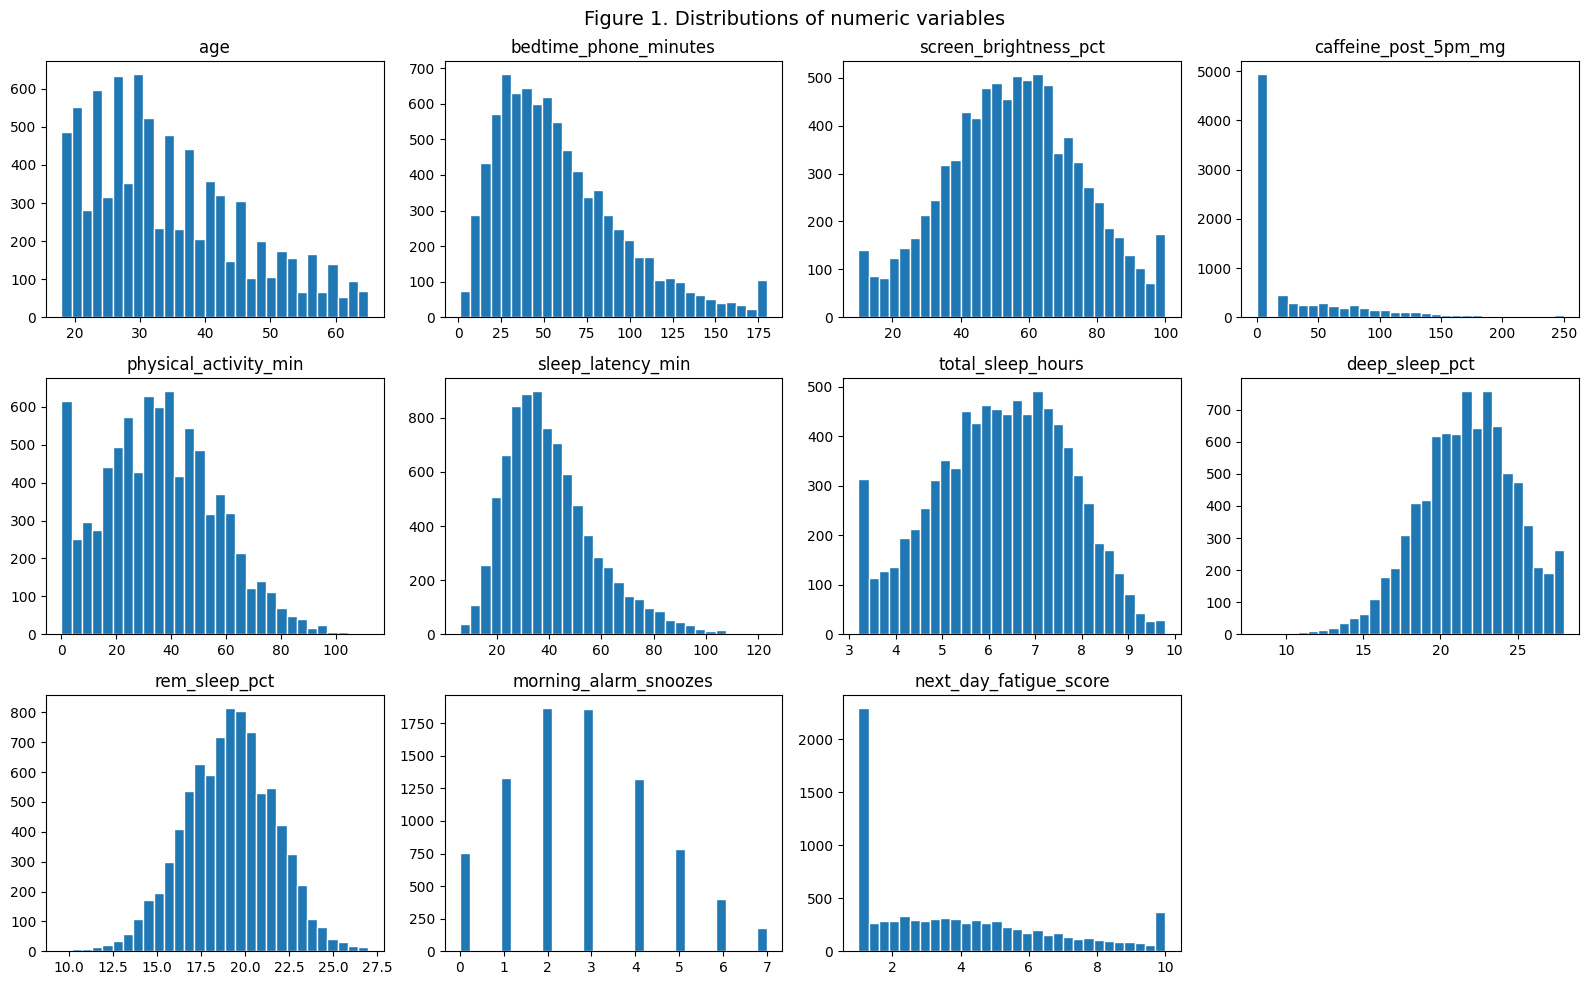

In [18]:
# %% Cell 2: Figure 1, histograms of all numeric variables
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.hist(eda[col], bins=30, edgecolor="white")
    ax.set_title(col)
for ax in axes.ravel()[len(numeric_cols):]:
    ax.axis("off")
fig.suptitle("Figure 1. Distributions of numeric variables", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig1_histograms.png", dpi=150)
plt.show()

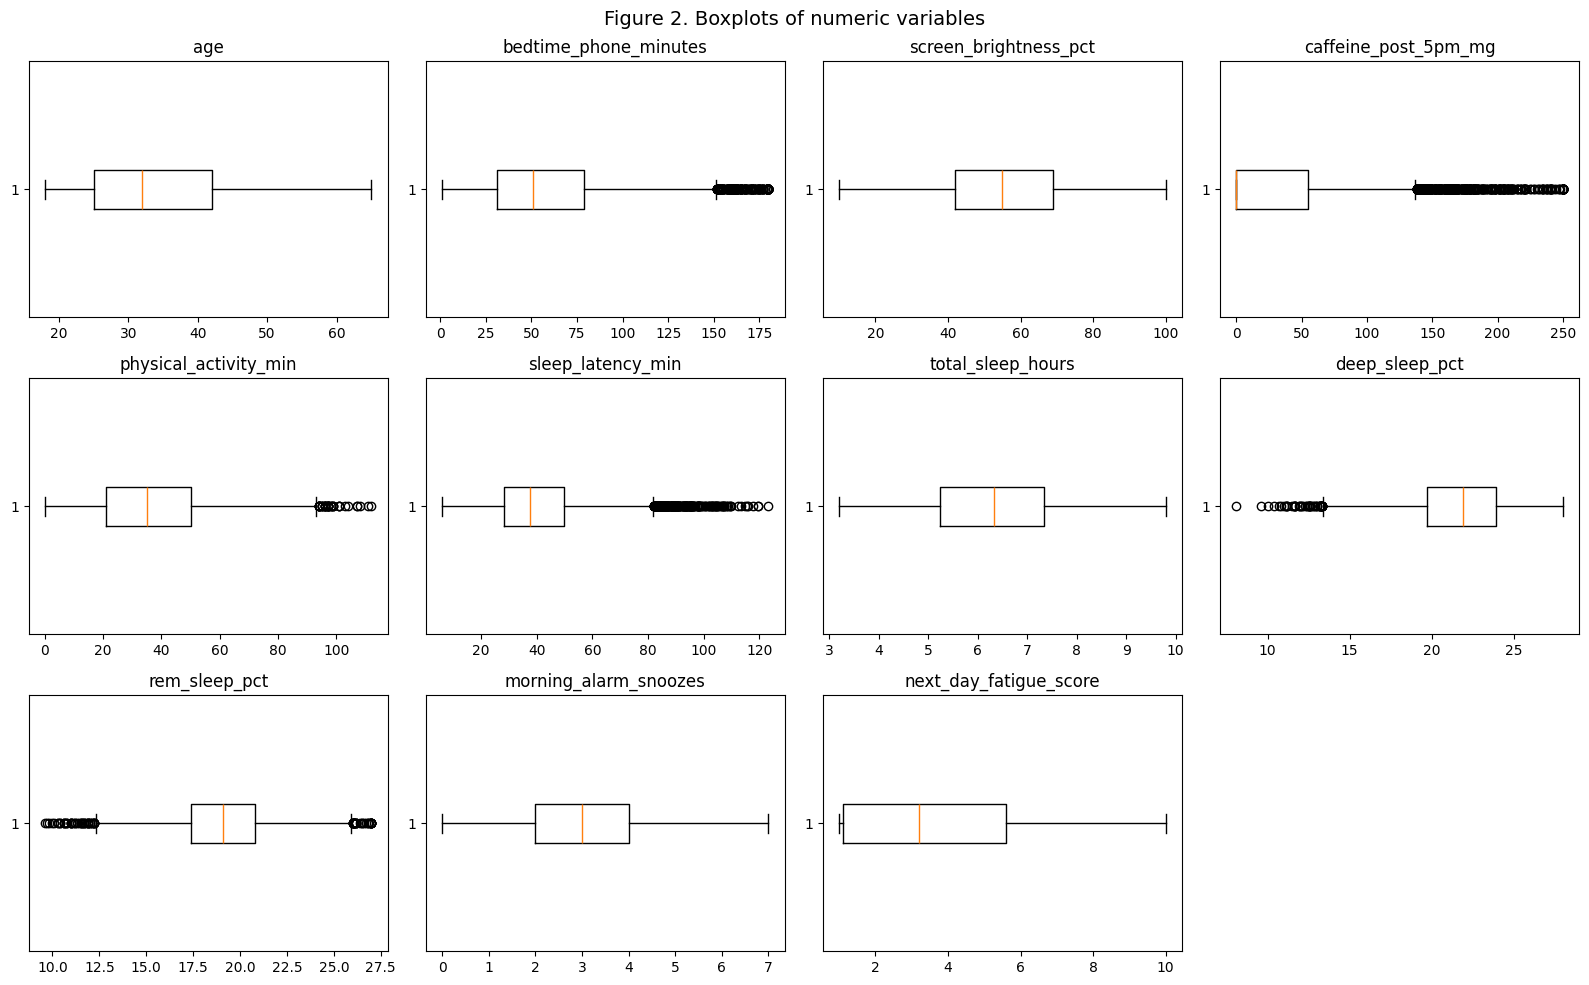

In [19]:
# %% Cell 3: Figure 2, boxplots of all numeric variables
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.boxplot(eda[col], vert=False)
    ax.set_title(col)
for ax in axes.ravel()[len(numeric_cols):]:
    ax.axis("off")
fig.suptitle("Figure 2. Boxplots of numeric variables", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig2_boxplots.png", dpi=150)
plt.show()

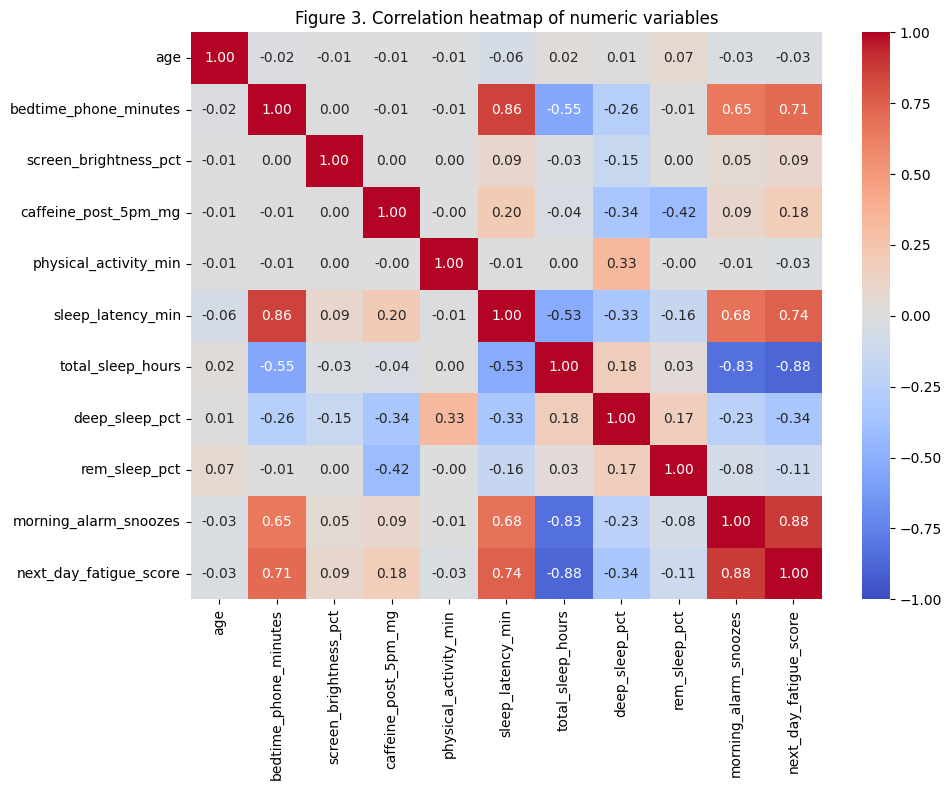

In [20]:
# %% Cell 4: Figure 3, correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(eda[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Figure 3. Correlation heatmap of numeric variables")
plt.tight_layout()
plt.savefig("figures/fig3_correlation.png", dpi=150)
plt.show()

In [21]:
# %% Cell 5: confirm the four key correlations
checks = [("bedtime_phone_minutes", "sleep_latency_min", 0.86),
          ("bedtime_phone_minutes", "next_day_fatigue_score", 0.71),
          ("total_sleep_hours", "next_day_fatigue_score", -0.88),
          ("sleep_latency_min", "total_sleep_hours", -0.53)]
for a, b, expected in checks:
    print(f"{a} vs {b}: {eda[a].corr(eda[b]):.2f} (expected about {expected})")

bedtime_phone_minutes vs sleep_latency_min: 0.86 (expected about 0.86)
bedtime_phone_minutes vs next_day_fatigue_score: 0.71 (expected about 0.71)
total_sleep_hours vs next_day_fatigue_score: -0.88 (expected about -0.88)
sleep_latency_min vs total_sleep_hours: -0.53 (expected about -0.53)


## Step 2 EDA: observations and interpretation

### Distributions (Figures 1 and 2)

**1. Fatigue is piled up at both ends.** About 24.8% of scores sit at 1.0 (2,110 rows) and about 3.7% at 10 (314 rows). The rest are spread thinly between them and skew toward the low end, with a median near 3.
- *Interpretation:* The score is censored: it cannot go below 1 or above 10. A standard regression assumes an unbounded outcome, so it would be pulled toward the middle and could predict values outside 1 to 10. This justifies the quantile regression and hurdle models.

**2. Total sleep hours has a floor.** There is a spike at 3.2 hours (about 2.8% of rows), while the rest is roughly bell-shaped around 6 to 7 hours.
- *Interpretation:* 3.2 looks like a recorded minimum, so the true sleep of these users may be shorter. The effect of very short sleep may be understated. The `sleep_at_floor` flag can be used to check this.

**3. Several habit variables are skewed or zero-heavy.** Caffeine after 5pm is 0 mg for more than half of users, with a long right tail up to about 250 mg. Physical activity has a spike at 0 minutes and a right tail. Bedtime phone minutes is right-skewed with a small pile-up at the 180-minute cap.
- *Interpretation:* Averages can be misleading for these variables, since many users have no caffeine or no activity. Tree models handle this well, but linear models may need care. For the recommender, 0 is a hard limit: caffeine and activity cannot be lowered below zero.

**4. Sleep latency is right-skewed.** Most users fall asleep in 20 to 50 minutes, with a long tail past 100 minutes.
- *Interpretation:* Linear models may fit the long tail poorly. Check the residuals, and consider a log transform if they look uneven.

**5. Some variables are fairly well-behaved.** Age is concentrated in the 20s and 30s (range 18 to 65). Screen brightness and REM sleep are roughly bell-shaped, and deep sleep is slightly left-skewed. Morning alarm snoozes is a discrete count from 0 to 7, peaking at 2 and 3.
- *Interpretation:* These variables need no special transformation. Snoozes is a count, so Ridge is acceptable as a baseline, but a count-aware model may fit better. Because most users are young adults, the results may not apply to older people.

**6. Outliers appear in the boxplots** for phone minutes (above about 150), caffeine (above about 140 mg), physical activity (above about 95), sleep latency (many points above about 80), deep sleep (low end), and REM sleep (both ends). Age, screen brightness, sleep hours, snoozes, and fatigue show none.
- *Interpretation:* These are plausible extreme values and not errors, so they are kept. Tree models are robust to them, and the bootstrap confidence intervals in the mediation step will show whether they affect the results.

### Correlations (Figure 3)

**7. The four expected correlations are confirmed:** phone minutes vs latency 0.86, phone minutes vs fatigue 0.71, sleep hours vs fatigue -0.88, and latency vs sleep hours -0.53.
- *Interpretation:* The data matches the earlier checks. More phone time goes with longer time to fall asleep, shorter sleep, and more fatigue, which fits the habits -> sleep -> fatigue pathway. These are associations and do not prove causation.

**8. Fatigue is most strongly tied to the sleep measures.** Besides sleep hours (-0.88), it correlates with morning alarm snoozes (0.88) and sleep latency (0.74). Phone minutes also correlates with snoozes (0.65) and with sleep hours (-0.55).
- *Interpretation:* The sleep measures sit closest to fatigue, which supports treating them as mediators. Phone minutes is also tied to the sleep measures, which suggests its effect travels largely through sleep.

**9. The sleep measures are correlated with each other.** Snoozes vs sleep hours is -0.83, and snoozes vs latency is 0.68.
- *Interpretation:* This multicollinearity makes individual coefficients less stable, and it will be harder to separate the latency and sleep-hours paths in the serial mediation. Use bootstrap confidence intervals, report VIF, and interpret each path cautiously.

**10. The habits are almost uncorrelated with each other** (all near 0), and age is near 0 with everything. Phone minutes is the dominant habit, and the others are weaker.
- *Interpretation:* Each habit's effect can be separated cleanly, so one habit is unlikely to distort the mediation estimate of another. The counterfactual recommender can change one habit at a time in a realistic way. Such clean independence is also a hint that the data may be synthetic, which belongs in the limitations.

**11. Caffeine and activity link mainly to deep and REM sleep.** Caffeine has weak links to latency (0.20) and fatigue (0.18), but moderate links to deep sleep (-0.34) and REM sleep (-0.42). Physical activity is near 0 with fatigue (-0.03) and correlates only with deep sleep (0.33).
- *Interpretation:* Deep and REM sleep are not mediators in the pipeline, so the indirect effects of caffeine and activity through latency and sleep hours will look small. That does not mean these habits don't matter. It supports the planned sensitivity analysis with deep and REM sleep included.

### Note for the next steps

**12. Morning alarm snoozes correlates 0.88 with fatigue**, as strongly as sleep hours.
- *Interpretation:* Snoozes may carry much of the signal, yet it is only a Stage 1 target and not a mediator. The team should confirm that this is a deliberate choice and state the reason in the report.